# Fig. 3(c,d): response bounds for the transcriptional-regulation model

Random three-state promoter networks with random expression levels; the activator concentration enters through a single transition. (c) Relative response of the expression level (Eq. 14). (d) Response resolution (Eq. 15).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join('..', 'lib')))
OUT = os.path.abspath(os.path.join('..', 'figures'))
os.makedirs(OUT, exist_ok=True)

import numpy as np
np.random.seed(2026)

## Model and helper functions

In [2]:
from ftMarkov import *
import matplotlib.pyplot as plt
import numpy as np

def generate_matrix(E,B,F):
    size = np.shape(E)[0]
    # Compute rates
    W = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            if i != j:
                W[i,j] = np.exp(-(B[i,j] - E[j] - F[i,j]/2))
    W = W - np.diag(W.sum(axis=0))
    return W

def generate_random_network(size, scale=12.0,seed=None):
    if seed is not None:
        np.random.seed(seed)
    """Generate random network parameters and transition rates"""
    # Generate parameters
    E = (np.random.rand(size)-0.5)*scale
    B = (np.random.rand(size, size)-0.5)*scale
    B = (B + B.T) / 2  # symmetric
    F = (np.random.rand(size,size)-0.5)*scale
    F = (F - F.T) / 2  # antisymmetric
    W = generate_matrix(E,B,F)
    return W, E, B, F

def compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable, response_fn,return_linear_response=False):
    """Compute response for a single edge over different perturbation strengths, using a user-specified response function"""
    # = MarkovNet(W)
    markov = MarkovNet( generate_matrix(E, B, F))
    #markov_small = W_small)
    original_pss = markov.pss
    # if postive:
    #     observable = np.random.randn(len(W))#np.exp(-8*np.random.randn(len(W)))#np.random.randn(len(W))
    # else:
    #     observable = #(np.random.randn(len(W)) - 0.5)
    original_obs = np.sum(observable * original_pss)
    original_obs_sq = np.sum((observable**2) * original_pss)
    original_variance = original_obs_sq - original_obs**2
    # First compute linear response (eps->0 limit)
    eps_small = 1e-4
    E_small, B_small, F_small = E.copy(), B.copy(), F.copy()
    
    if perturb_type == 'B':
        B_small[m,n] += eps_small
        B_small[n,m] += eps_small
    elif perturb_type == 'F':
        F_small[m,n] += eps_small
        F_small[n,m] -= eps_small
    elif perturb_type == 'E':
        E_small[m] += eps_small
    elif perturb_type == 'A':
        # For A perturbation, we directly perturb the A matrix element
        # A[i,j] = B[i,j] - E[j] - F[i,j]/2
        # So perturbing A[m,n] by eps_small is equivalent to perturbing B[m,n] by eps_small
        B_small[m,n] += eps_small
        
    W_small = generate_matrix(E_small, B_small, F_small)
    markov_small = MarkovNet(W_small)
    new_obs_small = np.sum(observable * markov_small.pss)
    linear_response = (new_obs_small - original_obs) / eps_small
    
    responses = []
    for eps in eps_range:
        E_new, B_new, F_new = E.copy(), B.copy(), F.copy()
        if perturb_type == 'B':
            B_new[m,n] += eps
            B_new[n,m] += eps
        elif perturb_type == 'F':
            F_new[m,n] += eps
            F_new[n,m] -= eps
        elif perturb_type == 'E':
            E_new[m] += eps
        elif perturb_type == 'A':
            # For A perturbation, we directly perturb the A matrix element
            # A[i,j] = B[i,j] - E[j] - F[i,j]/2
            # So perturbing A[m,n] by eps is equivalent to perturbing B[m,n] by eps
            B_new[m,n] += eps
        
        W_new = generate_matrix(E_new, B_new, F_new)
        markov_new = MarkovNet(W_new)
        new_pss = markov_new.pss
        new_obs = np.sum(observable * new_pss)
        # Calculate variance in perturbed case
        new_obs_sq = np.sum((observable**2) * new_pss)
        new_variance = new_obs_sq - new_obs**2
        
        # compute the response with the user-supplied function
        response = response_fn(original_obs, new_obs, eps,linear_response, original_variance, new_variance)
        responses.append(response)
    if return_linear_response:
        return responses, linear_response
    else:
        return responses


def plot_results(all_responses, eps_range, perturb_type):
    """Create plot of responses vs perturbation strength"""
    # Define colors for different perturbation types
    colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
    # Plot response for each network
    for i, responses in enumerate(all_responses):
        plt.plot(eps_range, responses, '-',
                alpha=0.2, color=colors[perturb_type])
    
    #plt.xlabel(f'Perturbation Strength ($\Delta {perturb_type}$)')
    #plt.ylabel(r'Current Response / Linear Response, $\frac{\Delta J_{mn}}{e^{\Delta F_e}-1}\left(\partial_{F_e}J_{mn}\right)^{-1}$')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    return plt.gcf()


## Fig. 3(c)

Computing responses for 300 networks...
Network 0/300
Network 10/300
Network 20/300
Network 30/300
Network 40/300
Network 50/300
Network 60/300
Network 70/300
Network 80/300
Network 90/300
Network 100/300


Network 110/300
Network 120/300
Network 130/300
Network 140/300
Network 150/300
Network 160/300
Network 170/300
Network 180/300
Network 190/300
Network 200/300
Network 210/300


Network 220/300
Network 230/300
Network 240/300
Network 250/300
Network 260/300
Network 270/300
Network 280/300
Network 290/300
Creating plot...


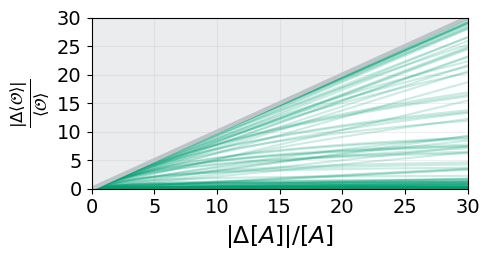

In [3]:
def response_fn(original_obs, new_obs, eps, linear_response, original_variance,new_variance):
    return np.abs(new_obs-original_obs) /original_obs

# Parameters
SIZE = 3
N_NETWORKS = 300  # Number of different networks to generate
eps_range = np.linspace(-np.log(41), 0, 50)
da_range = np.exp(-eps_range)-1
bound_color = '#BDC3C7'  
# List of perturbation types to try in random order
perturb_types = ['B', 'F', 'B']
perturb_types = [ 'A']
np.random.shuffle(perturb_types)

# Dictionary to store responses for each type
all_responses_dict = {ptype: [] for ptype in perturb_types}

# Colors for each perturbation type
colors = {'B': '#8B0000', 'F': '#1f77b4', 'E': '#2ca02c','A':'#FF6B6B'}

print(f"Computing responses for {N_NETWORKS} networks...")
for i in range(N_NETWORKS):
    if i % 10 == 0:
        print(f"Network {i}/{N_NETWORKS}")
        
    # Generate random network
    W, E, B, F = generate_random_network(SIZE,scale=24)
    
    # Choose random edge to perturb
    while True:
        m = 1#
        n = 0#np.random.randint(0, SIZE)
        if m != n and W[m,n] != 0 and W[n,m] != 0:
            break
            
    # Compute responses for each perturbation type
    for perturb_type in perturb_types:
        #observable = np.exp(-8*(np.random.randn(len(W)) ))#*(np.random.rand(len(W))-0.5)
        observable = np.zeros(len(W))
        observable[2] = np.random.rand()
        observable[1] = np.random.rand()
        #observable = np.random.rand(len(W))
        #observable = np.random.rand(len(W))
        #
        responses = compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable,response_fn)
        all_responses_dict[perturb_type].append(responses)

# Plot results for each perturbation type
print("Creating plot...")
plt.figure(figsize=(5, 2.7))
for perturb_type in perturb_types:
    plot_results(all_responses_dict[perturb_type], da_range, perturb_type)

# Add legend
legend_elements = [plt.Line2D([0], [0], color=colors[pt], label=f'{pt} perturbation', alpha=0.5) 
                    for pt in perturb_types]
legend_elements.extend([
    plt.Line2D([0], [0], color='#4B9FE1', linestyle='--', linewidth=3, label=r'$e^{\Delta X}$'),
    plt.Line2D([0], [0], color='#FF6B6B', linestyle='--', linewidth=3, label=r'$e^{-\Delta X}$')
])
#plt.legend(handles=legend_elements)
#
# Add bounds
#plt.plot(da_range,np.exp(eps_range)-1,'--', linewidth=3,color='#4B9FE1')  # brighter blue
plt.plot(da_range,np.exp(-eps_range)-1,'-', linewidth=3,color=bound_color)  # brighter red
plt.fill_between(da_range,np.exp(-eps_range)-1, np.exp(-np.min(eps_range))-1, alpha=0.3, color=bound_color)
# Set y-axis to logarithmic scale
#plt.yscale('log')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel(r'${|\Delta[A]|}/{[A]}$',fontsize=17)
plt.xlim(0,30)
plt.ylim(0,30)
plt.ylabel(r'$\frac{|\Delta\langle \mathcal{O}\rangle|}{\langle \mathcal{O}\rangle}$',fontsize=17)
#plt.ylabel(r'$|\Delta\langle \mathcal{O}\rangle|/\langle \mathcal{O}\rangle$')
#plt.gca().set_aspect(1)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig3c_relative_response_bound.svg'),bbox_inches='tight')
plt.show()

## Fig. 3(d): response along a single edge

In [4]:
def compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable, response_fn,return_linear_response=False):
    """Compute response for a single edge over different perturbation strengths, using a user-specified response function"""
    # = MarkovNet(W)
    markov = MarkovNet( generate_matrix(E, B, F))
    #markov_small = W_small)
    original_pss = markov.pss
    # if postive:
    #     observable = np.random.randn(len(W))#np.exp(-8*np.random.randn(len(W)))#np.random.randn(len(W))
    # else:
    #     observable = #(np.random.randn(len(W)) - 0.5)
    original_obs = np.sum(observable * original_pss)
    original_obs_sq = np.sum((observable**2) * original_pss)
    original_variance = original_obs_sq - original_obs**2
    # First compute linear response (eps->0 limit)
    eps_small = 1e-4
    E_small, B_small, F_small = E.copy(), B.copy(), F.copy()
    
    if perturb_type == 'B':
        B_small[m,n] += eps_small
        B_small[n,m] += eps_small
    elif perturb_type == 'F':
        F_small[m,n] += eps_small
        F_small[n,m] -= eps_small
    elif perturb_type == 'E':
        E_small[m] += eps_small
    elif perturb_type == 'A':
        # For A perturbation, we directly perturb the A matrix element
        # A[i,j] = B[i,j] - E[j] - F[i,j]/2
        # So perturbing A[m,n] by eps_small is equivalent to perturbing B[m,n] by eps_small
        B_small[m,n] += eps_small
        
    W_small = generate_matrix(E_small, B_small, F_small)
    markov_small = MarkovNet(W_small)
    new_obs_small = np.sum(observable * markov_small.pss)
    linear_response = (new_obs_small - original_obs) / eps_small
    
    responses = []
    for eps in eps_range:
        E_new, B_new, F_new = E.copy(), B.copy(), F.copy()
        if perturb_type == 'B':
            B_new[m,n] += eps
            B_new[n,m] += eps
        elif perturb_type == 'F':
            F_new[m,n] += eps
            F_new[n,m] -= eps
        elif perturb_type == 'E':
            E_new[m] += eps
        elif perturb_type == 'A':
            # For A perturbation, we directly perturb the A matrix element
            # A[i,j] = B[i,j] - E[j] - F[i,j]/2
            # So perturbing A[m,n] by eps is equivalent to perturbing B[m,n] by eps
            B_new[m,n] += eps
        
        W_new = generate_matrix(E_new, B_new, F_new)
        markov_new = MarkovNet(W_new)
        new_pss = markov_new.pss
        new_obs = np.sum(observable * new_pss)
        # Calculate variance in perturbed case
        new_obs_sq = np.sum((observable**2) * new_pss)
        new_variance = new_obs_sq - new_obs**2
        
        # compute the response with the user-supplied function
        response = response_fn(original_obs, new_obs, eps,linear_response, original_variance, new_variance)
        responses.append(response)
    if return_linear_response:
        return responses, linear_response
    else:
        return responses

## Fig. 3(d)

Computing responses for 200 networks...
Network 0/200
Network 10/200
Network 20/200
Network 30/200
Network 40/200
Network 50/200
Network 60/200
Network 70/200
Network 80/200
Network 90/200


Network 100/200
Network 110/200
Network 120/200
Network 130/200
Network 140/200
Network 150/200
Network 160/200
Network 170/200
Network 180/200
Network 190/200
Creating plot...


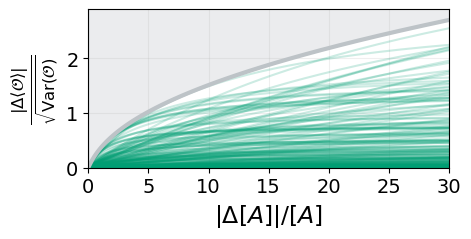

In [5]:
if __name__ == "__main__":
    def response_fn(original_obs, new_obs, eps, linear_response, original_variance,new_variance):
        return np.abs(new_obs - original_obs) /np.sqrt(original_variance)
    # Parameters
    SIZE = 3
    N_NETWORKS = 200  # Number of different networks to generate
    eps_range = np.linspace(-np.log(31), 0, 50)
    da_range = np.exp(-eps_range)-1
    bound_color = '#BDC3C7'   
    # List of perturbation types to try in random order
    perturb_types = ['B', 'F', 'E']
    perturb_types = ['A']
    np.random.shuffle(perturb_types)
    
    # Dictionary to store responses for each type
    all_responses_dict = {ptype: [] for ptype in perturb_types}
    
    # Colors for each perturbation type
    colors = {'B': '#8B0000', 'A': '#1f77b4', 'E': '#2ca02c'}
    
    print(f"Computing responses for {N_NETWORKS} networks...")
    for i in range(N_NETWORKS):
        if i % 10 == 0:
            print(f"Network {i}/{N_NETWORKS}")
            
        # Generate random network
        W, E, B, F = generate_random_network(SIZE)
        
        # Choose random edge to perturb
        while True:
            m = np.random.randint(0, SIZE)
            n = np.random.randint(0, SIZE)
            if m != n and W[m,n] != 0 and W[n,m] != 0:
                break
                
        # Compute responses for each perturbation type
        for perturb_type in perturb_types:
            observable = np.array([0,1,1])
            observable = np.zeros(len(W))
            observable[2] = np.random.rand()
            observable[1] = np.random.rand()
            responses = compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable,response_fn)
            all_responses_dict[perturb_type].append(responses)
    plt.figure(figsize=(5, 2.5))
    # Plot results for each perturbation type
    print("Creating plot...")   
    for perturb_type in perturb_types:
        plot_results(all_responses_dict[perturb_type],da_range, perturb_type)
    
    # Add legend
    legend_elements = [plt.Line2D([0], [0], color=colors[pt], label=f'{pt} perturbation', alpha=0.5) 
                      for pt in perturb_types]
    legend_elements.extend([
        #plt.Line2D([0], [0], color='#4B9FE1', linestyle='--', linewidth=3, label='1'),
        plt.Line2D([0], [0], color='#FF6B6B', linestyle='--', linewidth=3, label=r'$\sinh(\Delta X/2)$')
    ])
    #plt.legend(handles=legend_elements, fontsize=14)

    # Add bounds
    #plt.plot(eps_range, np.ones(eps_range.shape)/2,'--', linewidth=3,color='#4B9FE1')  # brighter blue
    plt.plot(da_range, np.abs(np.sinh(eps_range/2)),'-', linewidth=3,color=bound_color)  # brighter red
    plt.fill_between(da_range, np.abs(np.sinh(eps_range/2)),  np.max(np.abs(np.sinh(eps_range/2)))+.3, alpha=0.3, color=bound_color)
    #plt.plot(eps_range, np.sqrt((np.exp(eps_range)-1))/2,'-', linewidth=3,color='b')  # brighter red
    # plt.plot(eps_range, (np.exp(eps_range)-1)/2,'-', linewidth=3,color='g')  # brighter red
    plt.xlabel(r'$|\Delta[A]|/[A]$', fontsize=17)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.ylim(0, np.max(np.abs(np.sinh(eps_range/2)))+.2)
    plt.xlim(0,30)
    
    #plt.grid(False)
    #plt.legend(fontsize=14)
    #plt.ylabel(r'Response / Noise, $\frac{|\Delta \langle \mathcal{O}\rangle|}{e^{\Delta X/2}-e^{-\Delta X/2}}\frac{1}{\sqrt{Var(\mathcal{O})} }$')
    plt.ylabel(r'$\frac{|\Delta \langle \mathcal{O}\rangle|}{\sqrt{\mathrm{Var}(\mathcal{O})} }$', fontsize=17)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, 'Fig3d_response_resolution_bound.svg'),bbox_inches='tight')
    #plt.gca().set_aspect(2)
    #plt.ylim(0,1)
    plt.show()